# WSCC 9 bus a trois machines, avec trois reseaux de distribution CIGRE

Le reseau de transport **WSCC 9 bus** d'Anderson et Fouad, tel quel : trois
**machines synchrones**, leur dispatch d'origine, aucun convertisseur. Chacun de
ses trois bus de charge alimente, par un poste 230/110 kV, un **reseau de
distribution CIGRE MT** complet avec ses deux departs et ses quatorze bus.

C'est le point de depart de l'etude `python/etudes/transition_ibr.ipynb` : un
systeme entierement synchrone, auquel on ajoute ensuite des GFL, puis des GFM
dans la distribution, puis dont on remplace les machines de transport par des
GFM. Pris seul, ce notebook donne le reseau de reference de cette transition.

**Echelle de puissance.** Un reseau CIGRE porte 25,8 MW de charge. Le bus 5 en
consomme 125, les bus 6 et 8 90 et 100 : les postes alimentent donc `K = 4`, `3`
et `3` reseaux CIGRE identiques, agreges en un seul chacun. La charge residuelle
du bus WSCC est ce que la distribution ne porte pas, **en P comme en Q**, si bien
que chaque bus de charge garde exactement sa consommation WSCC : le point de
fonctionnement du transport est celui du reseau d'origine, et les modes
electromecaniques sortent bien a 2,21 et 2,01 Hz.

**Plan de tension.** Les trois postes sources portent un gradin de condensateurs
(35, 25 et 25 Mvar) qui compense la consommation reactive de leurs
transformateurs ; sans lui, la moyenne tension descendrait a 0,90 pu. Aucune
prise hors nominale n'est necessaire. Le transport reste entre 1,018 et
1,040 pu, la moyenne tension entre 0,954 et 1,038 pu.

**Numerotation.** La distribution du bus 5 porte les numeros 100 a 114, celle du
bus 6 les numeros 200 a 214, celle du bus 8 les numeros 300 a 314 : bus 1x0 le
jeu de barres 110 kV, bus 1x1 a 1x14 les quatorze bus MT, et le poste 230/110 kV
appartient a la distribution. Un numero superieur ou egal a 100 signale donc la
distribution, comme dans `wscc9_cigre`.

```
  G1 (SM) --T1-- 1/4 ---- bus 6 ---- 9 --T3-- G3 (SM)
                  |         |        |
                bus 5 ---- bus 7 -- bus 8
                  |         |         |
              poste 1xx    T2        poste 3xx
                  |         |         |
            CIGRE (K=4)  G2 (SM)   CIGRE (K=3)
                            poste 2xx
                                 |
                           CIGRE (K=3)
```

Base systeme : **100 MVA, 60 Hz**. Distribution : trois CIGRE agreges K = 4, 3, 3.

Equivalent MATLAB : `matlab/G2Elin_V2/reseaux_test/reseaux_classiques/WSCC3SM_CIGRE3.m`.

### Comment comparer avec MATLAB

| Notebook (Python) | MATLAB |
|---|---|
| `net.run_loadflow()` | `net.Load_flow(Y_DER, false)` |
| `net.build_state_space()` | `net.buildGlobalModel()` |
| tableau modal ci-dessous | `displayModalAnalysis()` (`EigenVal_Table = 1`) |

Le tableau modal reprend les conventions MATLAB : participation
`p_ki = |v_gauche . v_droit|` normalisee par mode, `f_undamp = |lambda|/2pi`,
`f_damp = |Im(lambda)|/2pi`, `zeta = -Re(lambda)/|lambda|`, tri par
`Re(lambda)` decroissant, tous les modes conjugues inclus.

In [1]:
import sys
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import plotly.graph_objects as go


# Le paquet g2egrid est a la racine du projet (dossier parent de reseaux_test/).
ROOT = pathlib.Path.cwd()
ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from g2egrid import Network  # noqa: E402
from g2egrid.elements import (  # noqa: E402
    GFL1,
    GFL2,
    GFM1,
    GFM2,
    GFM3,
    GFM4,
    IB,
    Bus,
    ILoad,
    Line,
    PLoad,
    RLLoad,
    SynchronousMachine,
    SynchronousMachineTR,
    Transformer,
)

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 1. Construction du reseau

### 1.1 Donnees et assemblage

In [2]:
NOM_RESEAU = "WSCC3SM_CIGRE3"
F_ZOOM = 5.0

f0 = 60.0
Sb = 100e6

# --- Les trois departs de distribution ------------------------------------
#
# Chaque bus de charge de la WSCC porte un reseau CIGRE MT complet, agrege K
# fois derriere son poste 230/110 kV : agreger K reseaux identiques revient a
# multiplier les puissances par K et a diviser les impedances par K, si bien
# que les tensions, les pertes relatives et les dynamiques en pu restent
# celles d'un seul CIGRE. K est choisi pour que la distribution porte l'essentiel
# de la charge du bus, le reste demeurant une charge agregee.
#
#           prefixe  bus amont   K   charge WSCC du bus
DEPARTS = ((    100,        5,   4),
           (    200,        6,   3),
           (    300,        8,   3))
CHARGE_WSCC = {5: (125e6, 50e6), 6: (90e6, 30e6), 8: (100e6, 35e6)}
GRADIN = {100: 0.35, 200: 0.25, 300: 0.25}  # condensateurs des postes sources, pu

# Un reseau CIGRE MT : charges et lignes, numerotation RELATIVE au prefixe.
CIGRE_CHARGES = {  # bus relatif : (P_W, Q_var)
     1: (20.4e6, 1.0e6),  3: (550e3, 50e3),  4: (445e3, 50e3),  5: (750e3, 50e3),
     6:  (565e3,  50e3),  7:  (90e3, 50e3),  8: (605e3, 50e3),  9: (675e3, 50e3),
    10:  (570e3,  50e3), 11: (340e3, 50e3), 12: (205e3, 50e3), 13:  (40e3, 50e3),
    14:  (605e3,  50e3),
}
CIGRE_LIGNES = [  # (de, vers, km, R_ohm/km, X_ohm/km, B_S/km)
    ( 1,  2, 2.82, 0.501, 0.716, 47.493e-6), ( 2,  3, 4.42, 0.501, 0.716, 47.493e-6),
    ( 3,  4, 0.61, 0.501, 0.716, 47.493e-6), ( 4,  5, 0.56, 0.501, 0.716, 47.493e-6),
    ( 5,  6, 1.54, 0.501, 0.716, 47.493e-6), ( 7,  8, 1.67, 0.501, 0.716, 47.493e-6),
    ( 8,  9, 0.32, 0.501, 0.716, 47.493e-6), ( 9, 10, 0.77, 0.501, 0.716, 47.493e-6),
    (10, 11, 0.33, 0.501, 0.716, 47.493e-6), ( 3,  8, 1.30, 0.501, 0.716, 47.493e-6),
    (12, 13, 4.89, 0.510, 0.366,  3.172e-6), (13, 14, 2.99, 0.510, 0.366,  3.172e-6),
]
P_CIGRE = sum(P for P, _ in CIGRE_CHARGES.values())   # 25,84 MW
Q_CIGRE = sum(Q for _, Q in CIGRE_CHARGES.values())   #  1,60 Mvar

# BusType : 1 = slack, 2 = PV, 3 = PQ

# --- Transport : la WSCC 9 bus d'Anderson et Fouad, dispatch d'origine ------
Y_DER = [ # [BusID, BusType, V_base, V_pu, Theta_rad,  Pg_W, Qg_var,   Pl_W, Ql_var]
        (    1,       1,     16.5e3, 1.040,        0,      0,     0,      0,      0),  # G1
        (    2,       2,     18.0e3, 1.025,        0,  163e6,     0,      0,      0),  # G2
        (    3,       2,     13.8e3, 1.025,        0,   85e6,     0,      0,      0),  # G3
        (    4,       3,      230e3, 1.000,        0,      0,     0,      0,      0),
        (    5,       3,      230e3, 1.000,        0,      0,     0,      0,      0),  # + CIGRE 1xx
        (    6,       3,      230e3, 1.000,        0,      0,     0,      0,      0),  # + CIGRE 2xx
        (    7,       3,      230e3, 1.000,        0,      0,     0,      0,      0),
        (    8,       3,      230e3, 1.000,        0,      0,     0,      0,      0),  # + CIGRE 3xx
        (    9,       3,      230e3, 1.000,        0,      0,     0,      0,      0),
]

T_Lines_SI = []

T_Lines_pu = [
# T_Lines_pu : [ID, From, To, Length_km,   R_pu,   X_pu,   B_pu,  Un_V, Sb_VA]
              (  1,    4,  5,         1, 0.0100, 0.0850, 0.1760, 230e3, 100e6),
              (  2,    4,  6,         1, 0.0170, 0.0920, 0.1580, 230e3, 100e6),
              (  3,    5,  7,         1, 0.0320, 0.1610, 0.3060, 230e3, 100e6),
              (  4,    6,  9,         1, 0.0390, 0.1700, 0.3580, 230e3, 100e6),
              (  5,    7,  8,         1, 0.0085, 0.0720, 0.1490, 230e3, 100e6),
              (  6,    8,  9,         1, 0.0119, 0.1008, 0.2090, 230e3, 100e6),
]

T_Shunts = []   # T_Shunts : [ID, BusID, B_pu]  -- rempli par la boucle ci-dessous

T_Transfos = [
 # T_Transfos : [ID, From, To,  Sn_VA,   U1_V,  U2_V,   R_pu,   X_pu]
               (  1,    1,   4,  100e6, 16.5e3, 230e3,      0, 0.0576),  # G1
               (  2,    2,   7,  100e6, 18.0e3, 230e3,      0, 0.0625),  # G2
               (  3,    3,   9,  100e6, 13.8e3, 230e3,      0, 0.0586),  # G3
]

T_IBs = []

# T_SMs : [ID, BusID, Sn_VA]
T_SMs = [
    (  1,  1, 247.5e6),
    (  2,  2, 192.0e6),
    (  3,  3, 128.0e6),
]
SM_PARAMS = {}

T_GFM1s = []   # aucun convertisseur : c'est le point de depart de la transition
T_GFM2s = []
T_GFM3s = []
T_GFM4s = []
GFM_PARAMS = {}

T_GFL1s = []
T_GFL2s = []
GFL_PARAMS = {}

T_Loads = []

# --- Raccordement des trois departs ----------------------------------------
# La charge residuelle du bus WSCC est ce que la distribution ne porte pas, en
# P comme en Q : chaque bus de charge garde donc EXACTEMENT sa consommation
# WSCC, et le point de fonctionnement du transport est celui du reseau d'origine.
for prefixe, amont, K in DEPARTS:
    P_bus, Q_bus = CHARGE_WSCC[amont]
    Y_DER = [
        (b, t, Un, V, th, Pg, Qg, P_bus - K * P_CIGRE, Q_bus - K * Q_CIGRE)
        if b == amont else (b, t, Un, V, th, Pg, Qg, Pl, Ql)
        for b, t, Un, V, th, Pg, Qg, Pl, Ql in Y_DER
    ]
    Y_DER.append((prefixe, 3, 110e3, 1.0, 0, 0, 0, 0, 0))            # jeu de barres 110 kV
    for i in range(1, 15):                                            # 14 bus MT
        P, Q = CIGRE_CHARGES.get(i, (0.0, 0.0))
        Y_DER.append((prefixe + i, 3, 20e3, 1.0, 0, 0, 0, K * P, K * Q))
    for n, (i, j, km, R, X, B) in enumerate(CIGRE_LIGNES, start=1):
        T_Lines_SI.append((prefixe + n, prefixe + i, prefixe + j, km, R / K, X / K, B * K))
    T_Transfos += [
        (prefixe,     amont,   prefixe, K * 50e6, 230e3, 110e3,  0.003, 0.12),  # 230/110 kV
        (prefixe + 1, prefixe, prefixe +  1, K * 25e6, 110e3, 20e3, 0.0016, 0.12),  # depart 1
        (prefixe + 2, prefixe, prefixe + 12, K * 25e6, 110e3, 20e3, 0.0016, 0.12),  # depart 2
    ]
    T_Shunts.append((prefixe, prefixe, GRADIN[prefixe]))

In [3]:
# --- bases de tension par bus, lues dans Y_DER ---
UN = {int(r[0]): r[2] for r in Y_DER}

# --- capacite shunt de chaque bus : moitie de la charge des lignes qui y
#     aboutissent (schema en pi), comme C_half = B_pu/2 dans Network.m. Un bus
#     qui n'en recoit aucune devient un noeud ALGEBRIQUE a resistance de
#     causalite R = 100 pu (Node.m / setResistor(100)). ---
Cbus = {int(r[0]): 0.0 for r in Y_DER}
for _id, i, j, km, _r, _x, b_km in T_Lines_SI:
    b_pu = b_km * km * (UN[i] ** 2 / Sb)
    Cbus[i] += b_pu / 2.0
    Cbus[j] += b_pu / 2.0
for _id, i, j, _km, _r, _x, b_pu, Un, Sb_l in T_Lines_pu:
    b_pu = b_pu * (UN[i] ** 2 / Sb) / (Un ** 2 / Sb_l)  # base de la ligne -> base systeme
    Cbus[i] += b_pu / 2.0
    Cbus[j] += b_pu / 2.0
# compensation shunt propre a un bus (banc de condensateurs), qui s'ajoute a
# la charge capacitive des lignes. MATLAB n'a pas de colonne pour cela dans
# Y_DER : d'ou une table a part, plutot qu'une colonne en plus.
for _id, b, B_pu in T_Shunts:
    Cbus[b] += B_pu

# --- charges speciales de T_Loads : leur consommation s'ajoute a celle de
#     Y_DER dans le load flow ---
CHARGES_SPECIALES = {"I": ILoad, "P": PLoad}
S_spec = {int(r[0]): [0.0, 0.0] for r in Y_DER}
for _id, b, P, Q, typ in T_Loads:
    if typ not in CHARGES_SPECIALES:
        raise ValueError(f"T_Loads, charge {_id} : type '{typ}' inconnu ('I' ou 'P')")
    S_spec[b][0] += P
    S_spec[b][1] += Q

# --- assemblage du reseau
net = Network(f0=f0, Sb=Sb)

for bid, btype, Un, Vpu, theta, Pg, Qg, Pl, Ql in Y_DER:  # Y_DER
    net.add(
        Bus(
            int(bid),
            Un,
            btype=int(btype),
            V=Vpu,
            theta=theta,
            Pg=Pg,
            Qg=Qg,
            Pl=Pl + S_spec[int(bid)][0],
            Ql=Ql + S_spec[int(bid)][1],
            C=Cbus[int(bid)],
        )
    )

for lid, i, j, km, r_km, x_km, _b in T_Lines_SI:  # T_Lines_SI
    ZB = UN[i] ** 2 / Sb
    net.add(
        Line(
            f"L{int(lid)}_{i}_{j}", i, j, R=r_km * km / ZB, X=x_km * km / ZB, wb=net.wb
        )
    )

for lid, i, j, _km, r_pu, x_pu, _b, Un, Sb_l in T_Lines_pu:  # T_Lines_pu
    k = (Un ** 2 / Sb_l) / (UN[i] ** 2 / Sb)  # base de la ligne -> base systeme
    net.add(Line(f"L{int(lid)}_{i}_{j}", i, j, R=r_pu * k, X=x_pu * k, wb=net.wb))

# Une prise hors nominal se declare par U1_V/U2_V, comme dans Network.m :
# n = (U1/U2)/(Un_i/Un_j), egal a 1 quand U1, U2 sont les tensions des bus.
for tid, i, j, Sn, U1, U2, R, X in T_Transfos:  # T_Transfos
    k = (Sb / Sn) * (U1 / UN[i]) ** 2  # base du transfo -> base systeme
    n = (U1 / U2) / (UN[i] / UN[j])
    net.add(Transformer(f"T{int(tid)}_{i}_{j}", i, j, R=R * k, X=X * k, wb=net.wb, n=n))

for _id, b, Sn, _E, _th, R, X in T_IBs:  # T_IBs
    net.add(IB(f"IB{b}", b, R=R, X=X, wb=net.wb, Sn=Sn, Sb=Sb))

# Colonnes optionnelles Rt_pu, Xt_pu des tables de DER : transfo de
# raccordement INTEGRE a l'equipement. Sans elles, la machine n'a pas de
# transfo (a declarer dans T_Transfos) et le convertisseur garde son filtre
# R2/L2 par defaut.
for _id, b, Sn, *Tr in T_SMs:  # T_SMs
    if Tr:
        net.add(SynchronousMachineTR(f"SM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, Rt=Tr[0], Lt=Tr[1], **SM_PARAMS))
    else:
        net.add(SynchronousMachine(f"SM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **SM_PARAMS))

for T_GFM, GFM in ((T_GFM1s, GFM1), (T_GFM2s, GFM2), (T_GFM3s, GFM3), (T_GFM4s, GFM4)):  # T_GFM1s a T_GFM4s
    for _id, b, Sn, _Vdc, *Tr in T_GFM:
        tr = dict(R2_pu=Tr[0], L2_pu=Tr[1]) if Tr else {}
        net.add(GFM(f"GFM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **(GFM_PARAMS | tr)))

for T_GFL, GFL in ((T_GFL1s, GFL1), (T_GFL2s, GFL2)):  # T_GFL1s, T_GFL2s
    for _id, b, Sn, _Vdc, *Tr in T_GFL:
        tr = dict(R2_pu=Tr[0], L2_pu=Tr[1]) if Tr else {}
        net.add(GFL(f"GFL{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **(GFL_PARAMS | tr)))

# Charges classiques : colonnes Pl_W, Ql_var de Y_DER -> charge R-L a
# impedance constante (GenericLoad.m). Une inductance ne peut pas consommer
# un reactif negatif ou nul : condensateur dans T_Shunts, ou charge speciale.
n_rl = 0
for bid, *_, Pl, Ql in Y_DER:  # Y_DER : charges classiques
    if Pl == 0 and Ql == 0:
        continue
    if Ql <= 0:
        raise ValueError(
            f"bus {int(bid)} : Ql = {Ql:g} var. Une charge R-L demande Ql > 0 ; "
            "declarer le condensateur dans T_Shunts ou la charge dans T_Loads ('P' ou 'I')"
        )
    net.add(RLLoad(f"Load{int(bid)}", int(bid), P=Pl / Sb, Q=Ql / Sb, wb=net.wb))
    n_rl += 1

for lid, b, P, Q, typ in T_Loads:  # T_Loads : charges speciales
    net.add(CHARGES_SPECIALES[typ](f"Load{typ}{int(lid)}_{b}", b, P=P / Sb, Q=Q / Sb))

n_gfm = len(T_GFM1s) + len(T_GFM2s) + len(T_GFM3s) + len(T_GFM4s)
print(
    f"{NOM_RESEAU} : {len(Y_DER)} bus, "
    f"{len(T_Lines_SI) + len(T_Lines_pu)} ligne(s), {len(T_Transfos)} transfo(s), "
    f"{len(T_IBs)} bus infini, {len(T_SMs)} machine(s), {n_gfm} GFM, "
    f"{len(T_GFL1s) + len(T_GFL2s)} GFL, {n_rl} charge(s) R-L, "
    f"{len(T_Loads)} charge(s) speciale(s)"
)

WSCC3SM_CIGRE3 : 54 bus, 42 ligne(s), 12 transfo(s), 0 bus infini, 3 machine(s), 0 GFM, 0 GFL, 42 charge(s) R-L, 0 charge(s) speciale(s)


### 1.2 Load flow

In [4]:
lf = net.run_loadflow()
print(
    f"Load flow : converge en {lf.iterations} iterations (mismatch {lf.mismatch:.2e})\n"
)

print(
    f"{'bus':>4} {'|V| [pu]':>10} {'angle [deg]':>12} "
    f"{'P inj [pu]':>12} {'Q inj [pu]':>12}"
)
print("-" * 54)
for b, i in net._bus_index().items():
    print(
        f"{b:>4} {abs(lf.V[i]):>10.4f} {np.degrees(np.angle(lf.V[i])):>12.4f} "
        f"{lf.S[i].real:>12.4f} {lf.S[i].imag:>12.4f}"
    )
print(
    f"\nSomme des injections : P = {lf.S.real.sum():+.4f} pu, "
    f"Q = {lf.S.imag.sum():+.4f} pu  (= pertes)"
)

Load flow : converge en 6 iterations (mismatch 1.37e-14)

 bus   |V| [pu]  angle [deg]   P inj [pu]   Q inj [pu]
------------------------------------------------------
   1     1.0400       0.0000       0.7760       0.0606
   2     1.0250       8.7137       1.6300      -0.0895
   3     1.0250       4.1930       0.8500      -0.2444
   4     1.0375      -2.3409       0.0000       0.0000
   5     1.0177      -4.2390      -0.2164      -0.4360
   6     1.0315      -3.9584      -0.1248      -0.2520
   7     1.0352       3.2397      -0.0000       0.0000
   8     1.0303       0.2672      -0.2248      -0.3020
   9     1.0401       1.5481      -0.0000       0.0000
 100     1.0249      -7.6984       0.0000       0.0000
 101     1.0090     -14.4141      -0.8160      -0.0400
 102     0.9897     -15.6988       0.0000      -0.0000
 103     0.9599     -17.7933      -0.0220      -0.0020
 104     0.9584     -17.9078      -0.0178      -0.0020
 105     0.9574     -17.9871      -0.0300      -0.0020
 106   

## 2. Modele d'etat

Equilibre element par element (Newton sur `[f; g] = 0`), puis assemblage
global : cablage des ports par LFT, elimination des variables algebriques
par complement de Schur.

In [5]:
net.solve_equilibrium()
ss = net.build_state_space()

print(ss)
print(f"\n{len(ss.states)} etats, {len(ss.inputs)} entrees, {len(ss.outputs)} sorties")
print(f"stable : {ss.is_stable()}   max Re(lambda) = {ss.eig().real.max():+.4e}")

print("\nEtats par element :")
seen = []
for s in ss.states:
    owner = s.split(".")[0]
    if owner not in seen:
        seen.append(owner)
for owner in seen:
    noms = [s.split(".", 1)[1] for s in ss.states if s.startswith(owner + ".")]
    print(f"  {owner:<12} {len(noms):>3} : {', '.join(noms)}")

<StateSpace 429 etats, 91 entrees, 384 sorties | max Re(lambda)=+4.872e-12>

429 etats, 91 entrees, 384 sorties
stable : True   max Re(lambda) = +4.8719e-12

Etats par element :
  bus4           2 : vd, vq
  bus5           2 : vd, vq
  bus6           2 : vd, vq
  bus7           2 : vd, vq
  bus8           2 : vd, vq
  bus9           2 : vd, vq
  bus100         2 : vd, vq
  bus101         2 : vd, vq
  bus102         2 : vd, vq
  bus103         2 : vd, vq
  bus104         2 : vd, vq
  bus105         2 : vd, vq
  bus106         2 : vd, vq
  bus107         2 : vd, vq
  bus108         2 : vd, vq
  bus109         2 : vd, vq
  bus110         2 : vd, vq
  bus111         2 : vd, vq
  bus112         2 : vd, vq
  bus113         2 : vd, vq
  bus114         2 : vd, vq
  bus200         2 : vd, vq
  bus201         2 : vd, vq
  bus202         2 : vd, vq
  bus203         2 : vd, vq
  bus204         2 : vd, vq
  bus205         2 : vd, vq
  bus206         2 : vd, vq
  bus207         2 : vd, vq
  bus208  

### 2.1 Tableau modal

Une ligne par valeur propre, triee par partie reelle decroissante (modes les
plus lents d'abord), comme `displayModalAnalysis` en MATLAB : une paire
conjuguee occupe deux lignes. L'index `Mode` est l'indice `k` de `lam[k]`.

| Colonne | Definition |
|---|---|
| `Re`, `Im` | parties reelle [1/s] et imaginaire [rad/s] de la valeur propre |
| `f_und [Hz]` | frequence propre non amortie, `abs(lambda) / 2pi` |
| `f_dam [Hz]` | frequence d'oscillation, `abs(Im) / 2pi` |
| `zeta [%]` | amortissement, `-Re / abs(lambda)` |
| `Etat j`, `%j` | j-ieme etat le plus participant et sa participation `abs(v_ki . w_ik)`, normalisee a 100 % par mode |

In [6]:
lam, Vr = np.linalg.eig(ss.A)
Wl = np.linalg.inv(Vr)
Pf = np.abs(Vr.T) * np.abs(Wl)  # Pf[k, i] : participation de l'etat i au mode k
Pf = Pf / np.maximum(Pf.sum(axis=1, keepdims=True), 1e-30)
top3 = np.argsort(-Pf, axis=1)[:, :3]  # les trois etats les plus participants
k = np.arange(len(lam))

mag = np.abs(lam)
zeta = np.where(mag > 1e-10, -lam.real / np.where(mag > 1e-10, mag, 1.0), 0.0)

T_eig = pd.DataFrame(
    {
        "Re": lam.real,
        "Im": lam.imag,
        "f_und [Hz]": mag / (2 * np.pi),
        "f_dam [Hz]": np.abs(lam.imag) / (2 * np.pi),
        "zeta [%]": 100 * zeta,
    }
)
for j in range(3):
    T_eig[f"Etat {j + 1}"] = [ss.states[i] for i in top3[:, j]]
    T_eig[f"%{j + 1}"] = 100 * Pf[k, top3[:, j]]
T_eig = T_eig.iloc[np.argsort(-lam.real, kind="stable")]
T_eig.index.name = "Mode"



T_eig

,Re,Im,f_und [Hz],f_dam [Hz],zeta [%],Etat 1,%1,Etat 2,%2,Etat 3,%3
Mode,,,,,,,,,,,
336,2.612476e-11,0.0,4.157884e-12,0.0,0.0,SM1.theta,43.362131,SM2.theta,34.067961,SM3.theta,22.569908
342,-1.799446e-01,0.0,2.863907e-02,0.0,100.0,SM1.vpss,40.010718,SM2.vpss,28.996548,SM3.vpss,23.312733
343,-1.872456e-01,0.0,2.980107e-02,0.0,100.0,SM1.vpss,47.852680,SM2.vpss,45.473465,SM3.vpss,2.317386
344,-1.889712e-01,0.0,3.007571e-02,0.0,100.0,SM3.vpss,66.923195,SM2.vpss,19.421555,SM1.vpss,6.036336
341,-4.858830e-01,0.0,7.733067e-02,0.0,100.0,SM1.v1,40.897268,SM2.v1,24.986856,SM3.v1,19.197272
...,...,...,...,...,...,...,...,...,...,...,...
3,-3.050455e+05,0.0,4.854951e+04,0.0,100.0,T1_1_4.i_q,49.128285,SM1.phi_d,38.286705,T1_1_4.i_d,12.514417
5,-3.057249e+05,0.0,4.865763e+04,0.0,100.0,T2_2_7.i_q,56.373334,SM2.phi_q,32.455278,T2_2_7.i_d,11.095772
4,-3.143132e+05,0.0,5.002449e+04,0.0,100.0,T2_2_7.i_d,54.832041,SM2.phi_d,34.311994,T2_2_7.i_q,10.785793


### 2.2 Carte des valeurs propres

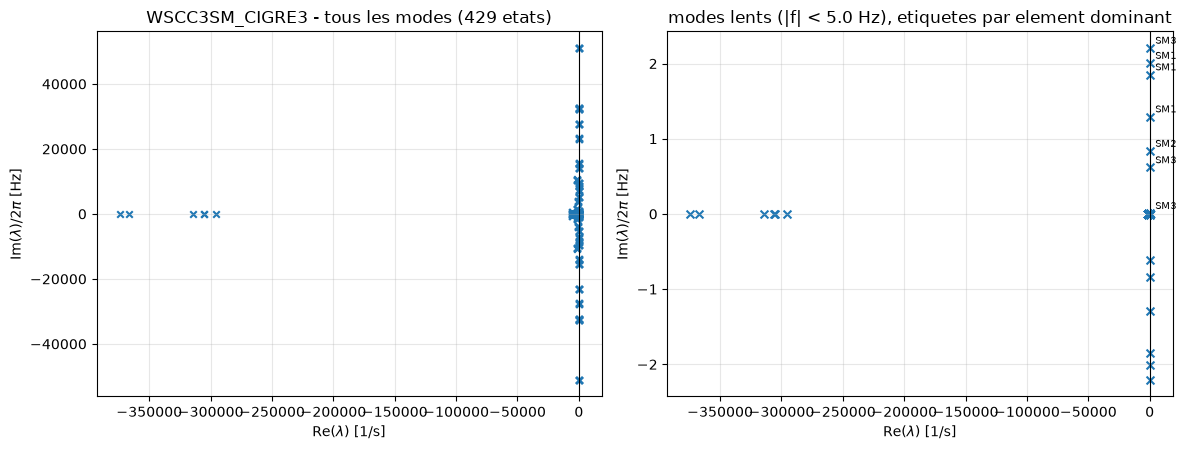

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

ax[0].scatter(lam.real, lam.imag / (2 * np.pi), s=22, marker="x")
ax[0].axvline(0.0, color="k", lw=0.8)
ax[0].set_xlabel("Re($\\lambda$) [1/s]")
ax[0].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[0].set_title(f"{NOM_RESEAU} - tous les modes ({len(lam)} etats)")
ax[0].grid(True, alpha=0.3)

zoom = np.abs(lam.imag) / (2 * np.pi) <= F_ZOOM
ax[1].scatter(lam[zoom].real, lam[zoom].imag / (2 * np.pi), s=32, marker="x")
for k in np.flatnonzero(zoom & (lam.imag > 1e-6)):
    ax[1].annotate(
        ss.states[top3[k, 0]].split(".")[0],
        (lam[k].real, lam[k].imag / (2 * np.pi)),
        fontsize=7,
        xytext=(4, 3),
        textcoords="offset points",
    )
ax[1].axvline(0.0, color="k", lw=0.8)
ax[1].set_xlabel("Re($\\lambda$) [1/s]")
ax[1].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[1].set_title(f"modes lents (|f| < {F_ZOOM} Hz), etiquetes par element dominant")
ax[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [8]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=T_eig["Re"], y=T_eig["Im"], mode="markers"))

fig.update_xaxes(range=[-1000, 10])
fig.update_yaxes(range=[-10, 1000])
fig.show()